          BASELINE LOGISTIC REGRESSION               
Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



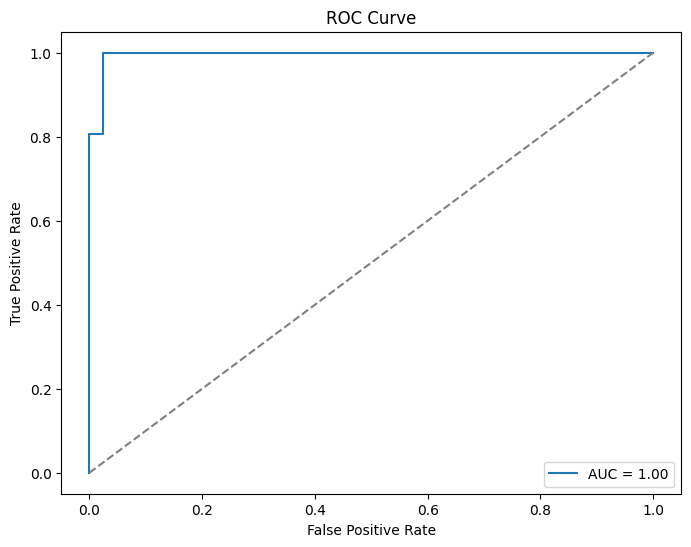


          BALANCED LOGISTIC REGRESSION               
Classification Report (Balanced):
              precision    recall  f1-score   support

           0       0.91      0.98      0.94        42
           1       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114


              DECISION TREE CLASSIFIER               
Classification Report (Decision Tree):
              precision    recall  f1-score   support

           0       0.85      0.93      0.89        42
           1       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



In [1]:
# Step 1: Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

# Step 2: Load Dataset
# Using the recommended Breast Cancer dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Step 3: Train-Test Split 
# stratify=y is used to preserve the class distribution[cite: 1]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 4: Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 5: Train Baseline Classification Model (Logistic Regression)[cite: 1]
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

# Step 6: Confusion Matrix & Classification Report[cite: 1]
print("=====================================================")
print("          BASELINE LOGISTIC REGRESSION               ")
print("=====================================================")
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 8: ROC Curve & AUC Score[cite: 1]
# Note: Step 7 is conceptual interpretation for your PDF report[cite: 1]
y_prob = model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

# Step 9: Handle Class Imbalance[cite: 1]
print("\n=====================================================")
print("          BALANCED LOGISTIC REGRESSION               ")
print("=====================================================")
model_balanced = LogisticRegression(class_weight="balanced", max_iter=1000)
model_balanced.fit(X_train_scaled, y_train)
y_pred_balanced = model_balanced.predict(X_test_scaled)
print("Classification Report (Balanced):")
print(classification_report(y_test, y_pred_balanced))

# Step 10: Compare with Another Classifier (Decision Tree)[cite: 1]
print("\n=====================================================")
print("              DECISION TREE CLASSIFIER               ")
print("=====================================================")
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train) # Trees do not require scaled features
y_pred_tree = tree.predict(X_test)
print("Classification Report (Decision Tree):")
print(classification_report(y_test, y_pred_tree))